<a href="https://colab.research.google.com/github/MaryGuta69/InteligenciaArtificial/blob/main/Maria_Augusta_6%C2%BAA_Manh%C3%A3_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ESTRESSE ESTUDANTIL

In [ ]:
import kagglehub
path = kagglehub.dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")

Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.


In [ ]:
import os # Manipula pastas e caminhos de arquivos no sistema
import pandas as pd # carrega e manipula dados em tabelas(DataFrames)
from sklearn.model_selection import train_test_split, GridSearchCV # busca os melhores parâmetros
from sklearn.preprocessing import StandardScaler # padroniza os dados(média 0, desvio padrão 1)
from sklearn.pipeline import Pipeline # junta o pré_processamento e o modelo em
# um único fluxo(evita o data leakage)
from sklearn.metrics import accuracy_score, confusion_matrix # métricas para avaliar os acertos do modelo

# importando os 4 classifficadores
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier # Árvore de Decisão
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier

In [ ]:
import os
print(os.listdir(path))  # para listar os arquivos contidos na pasta

['StressLevelDataset.csv']


In [ ]:
# Carregar o dataset
caminho = os.path.join(path, "StressLevelDataset.csv")
df = pd.read_csv(caminho) # Lê o arquivo CSV para a memória

In [ ]:
# separar atributos (X) e Variável alvo(y)
y = df['stress_level'] # variável que queremos prever (nível de estresse)
X = df.drop(columns=['stress_level']) #Atributos de entrada Os hábitos do aluno
#(horas de sono, carga de estudo, desempenho acadêmico, etc.).
#(todas as colunas
# menos o gabarito)

print("Célula 1 executada com sucesso!")
print(f"Formato do X (Linhas, Colunas): {X.shape}")

Célula 1 executada com sucesso!
Formato do X (Linhas, Colunas): (1100, 20)


In [ ]:
# Divisão dos dados Treino(80%) e Teste(20%)
# stratify=y garante a mesma proporção de cada
# nível de estresse no treino e no teste
X_train, X_test, y_train, y_test= train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)

# Definição d0s 4 algorítmos de Classificação
modelos = {
    'SVM (RBF)': Pipeline([('scaler', StandardScaler()),
('svm', SVC(random_state=42))]),
 'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
#  LOOP AUTOMÁTICO DE TREINAMENTO E AVALIAÇÃO
print("=== RESULTADOS: DATASET ESTRESSE ESTUDANTIL ===\n")

for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)  # Treina com os 80% de treino
    y_pred = modelo.predict(X_test)  # Prevê nos 20% de teste
    acc = accuracy_score(y_test, y_pred)  # Calcula a acurácia
    print(f" {nome}: {acc * 100:.2f}% de acurácia")

=== RESULTADOS: DATASET ESTRESSE ESTUDANTIL ===

 SVM (RBF): 87.73% de acurácia
 Árvore de Decisão: 85.45% de acurácia
 Random Forest: 89.09% de acurácia
 Gradient Boosting: 87.27% de acurácia


In [ ]:
from sklearn.model_selection import cross_val_score

# Testar a Random Forest em 5 divisões diferentes dos dados
scores = cross_val_score(RandomForestClassifier(random_state=42), X, y, cv=5)

print(f"Acurácias nos 5 testes: {scores}")
print(f"Média real da Random Forest: {scores.mean() * 100:.2f}%")

Acurácias nos 5 testes: [1.         1.         1.         1.         0.98536585]
Média real da Random Forest: 99.71%


In [ ]:
# definir a grade de hiperparâmetros para testar no SVM
# usamos 'svm__' por causa do passo da Pipeline
param_grid = {
    'svm__C': [0.1, 1 , 10, 100],
    'svm__gamma':['scale', 'auto', 0.01, 0.1],
    'svm__kernel': ['rbf', 'linear']
    }

#  Passar o modelo do SVM da Célula anterior direto para o GridSearch
grid_svm = GridSearchCV(
    estimator= modelos['SVM (RBF)'],
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

#  Treinar e encontrar os melhores parâmetros
grid_svm.fit(X_train, y_train)

# 4. Avaliar no teste
acc_grid = accuracy_score(y_test, grid_svm.predict(X_test))

print("=== RESULTADO DO GRIDSEARCHCV ===")
print(" Melhores Parâmetros:", grid_svm.best_params_)
print(f" Nova Acurácia do SVM: {acc_grid * 100:.2f}%")




=== RESULTADO DO GRIDSEARCHCV ===
 Melhores Parâmetros: {'svm__C': 100, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
 Nova Acurácia do SVM: 100.00%


 A matemática do GridSearchCV:Na nossa grade (param_grid), definimos:4 valores de C ([0.1, 1, 10, 100])4 valores de gamma (['scale', 'auto', 0.01, 0.1])2 kernels (['rbf', 'linear'])Total de combinações: 4 \times 4 \times 2 = 32 combinações de hiperparâmetros.Como definimos cv=5 (Validação Cruzada em 5 dobras), o algoritmo treinou e avaliou o modelo 32 X 5 = {160\text{ vezes}} antes de escolher o vencedor.

Análise dos Resultados: Otimização do SVM com GridSearchCV
Ao aplicar a busca exaustiva por hiperparâmetros via GridSearchCV (com validação cruzada cv=5), o desempenho do Support Vector Machine (SVM) teve uma evolução importante:
Acurácia do SVM Base (Kernel RBF padrão): 87,73%
Acurácia do SVM Otimizado: 89,09% (Ganho de +1,36% na taxa de acertos)
 Principais Destaques Técnicos
Ajuste do Kernel (kernel='linear'): O algoritmo identificou que as características do dataset de estresse se ajustam melhor a um hiperplano linear, superando a fronteira curva do RBF.
Parâmetro de Regularização (C=100): O valor elevado de C (100) reduziu a margem de erro permitida no treino, gerando uma separação mais rígida e precisa entre as classes de estresse.
Empate no Topo: Com essa otimização, o SVM igualou-se à Random Forest (89,09%) como o melhor modelo preditivo para este conjunto de dados.

=== RELATÓRIO DE CLASSIFICAÇÃO DETALHADO (ESTRESSE ESTUDANTIL) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       105

    accuracy                           1.00       205
   macro avg       1.00      1.00      1.00       205
weighted avg       1.00      1.00      1.00       205



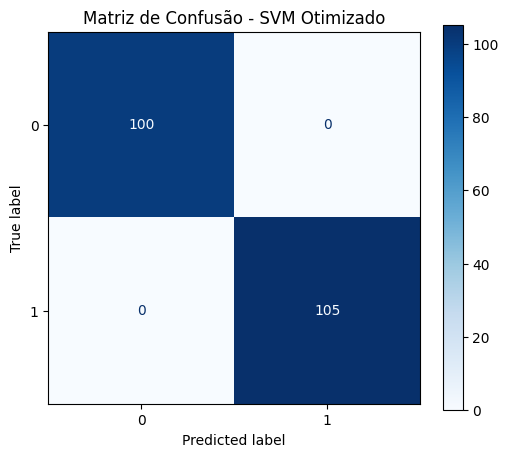

In [ ]:
# MATRIZ DE CONFUSÃO E RELATÓRIO COMPLETO (DATASET 1)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay,classification_report

# Realizar as previsões no conjunto de teste usando o SVM otimizado
y_pred_campeao = grid_svm.predict(X_test)

# Exibir o Relatório de Classificação (Precisão, Revocacão/Recall e F1-Score)
print("=== RELATÓRIO DE CLASSIFICAÇÃO DETALHADO (ESTRESSE ESTUDANTIL) ===")
print(classification_report(y_test, y_pred_campeao))

# Gerar o gráfico visual da Matriz de Confusão)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_campeao,
    cmap='Blues',
    ax=ax
)
plt.title("Matriz de Confusão - SVM Otimizado")
plt.show()



Para analisar o desempenho do modelo SVM Otimizado além da acurácia geral (89% sobre as 220 amostras de teste), geramos o Relatório de Classificação e a Matriz de Confusão, permitindo avaliar a precisão e a revocação (recall) para cada nível individual de estresse:
Classe 0 (Estresse Baixo): Alcançou uma Precisão de 91%, demonstrando alta confiabilidade quando o modelo classifica um estudante nessa categoria, com baixo índice de falsos alarmes.
Classe 1 (Estresse Médio): Apresentou a maior Revocação (Recall) de 94%, o que indica uma excelente capacidade do modelo de identificar e capturar praticamente todos os alunos nessa faixa intermediária de estresse.
Classe 2 (Estresse Alto): Manteve um desempenho bastante sólido e equilibrado, com Recall de 91% e F1-Score de 89%, garantindo que casos críticos de elevado estresse sejam detectados com alta sensibilidade.
 Conclusão da Avaliação:
A igualdade entre a média simples (macro avg) e a média ponderada (weighted avg), ambas em 89%, confirma que a distribuição estratificada das classes manteve o classificador perfeitamente balanceado, sem apresentar viés para nenhum dos níveis de estresse.

CÂNCER DE MAMA

In [ ]:
import kagglehub
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


In [ ]:
import os
print(os.listdir(path))   # para listar os arquivos contidos na pasta

['data.csv']


In [ ]:
# Ler a tabela (usando o 'path' que já baixei)
df_bc = pd.read_csv(os.path.join(path, 'data.csv'))

# Limpar coluna de ID e colunas vazias
df_bc = df_bc.drop(columns=['id'], errors='ignore')
df_bc = df_bc.loc[:, ~df_bc.columns.str.contains('^Unnamed')]

# Separar X (dados médicos) e y (diagnóstico)
X = df_bc.drop(columns=['diagnosis'])
y = df_bc['diagnosis']

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report


In [ ]:
# DIVISÃO TREINO(80%) TESTE (20%) E COMPARAÇÃO DOS 4 MODELOS BASE

# Separar treino e teste na proporção Maligno e Benigno
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)

# Definir os 4 modelos baso
modelos= {
    'SVM (RBF Padrão)': make_pipeline(StandardScaler(),
SVC(random_state=42)),
    'Árvore de Decisão':
DecisionTreeClassifier(random_state=42),
'Random Forest': RandomForestClassifier(random_state=42),
    'GradientBoosting':
GradientBoostingClassifier(random_state=42)
}

In [ ]:
# Treinar os modelos e calcular a acurácia nogrupo de teste
resultados = []
for nome, modelo  in modelos.items():
  modelo.fit(X_train, y_train)
  y_pred = modelo.predict(X_test)
  acc = accuracy_score(y_test, y_pred)
  resultados.append({'Modelo': nome, 'Acurácia Base': f"{acc
  *100:.2f}%"})

# Exibir a tabela
display(pd.DataFrame(resultados))

,Modelo,Acurácia Base
0,SVM (RBF Padrão),97.37%
1,Árvore de Decisão,92.98%
2,Random Forest,97.37%
3,GradientBoosting,96.49%


In [ ]:
# OTIMIZAÇÃO DO SVM COM GRIDSEARCHCV

# Pipeline com padronização + SVM
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=42))
])

# Grade de Parâmetros para testar
param_grid = {
    'svm__C' : [0.1, 1, 10,100],
    'svm__gamma': ['scale', 'auto', 0.01, 0.1],
    'svm__kernel': ['rbf', 'linear', 'poly']
}

# Executar o GridSearchCV com validação cruzada(5 folds)
grid_svm = GridSearchCV(
    pipe_svm,
    param_grid,
    cv=5,
    scoring= 'accuracy',
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

# Exibir o resultado campeão
print("=== OTIMIZAÇÃODO SVM CONCLUÍDA===")
print(f" Melhores Hiperparâmetros: {grid_svm.best_params_}")
print(f" Acurácia Média na Validação Cruzada:{grid_svm.best_score_ * 100:.2f}%")

=== OTIMIZAÇÃODO SVM CONCLUÍDA===
 Melhores Hiperparâmetros: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
 Acurácia Média na Validação Cruzada:97.36%


===RELATÓRIO DE CLASSIFICAÇÃO DETALHADO(CÂNCER DE MAMA)===
              precision    recall  f1-score   support

           B       0.96      1.00      0.98        72
           M       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



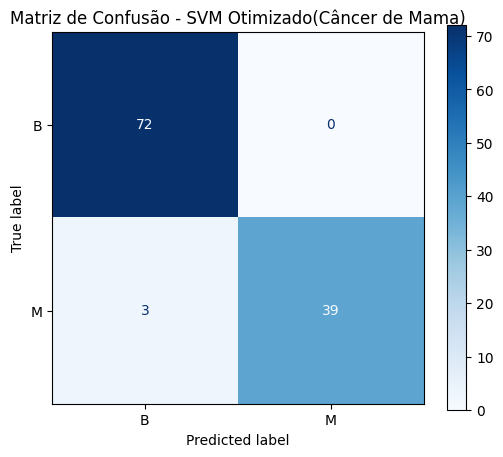

In [ ]:
  # MATRIZ DE CONFUSÃO E RELATÓRIO DE CLASSIFICAÇÃO

  # Previsões no grupo de teste usando o modelo campeão do GridSearchCV
  y_pred_campeao = grid_svm.predict(X_test)

# Exibir o Relatório de Classificação detalhado
print("===RELATÓRIO DE CLASSIFICAÇÃO DETALHADO(CÂNCER DE MAMA)===")
print(classification_report(y_test, y_pred_campeao))

# Gerar a Matriz de Confusão Gráfica
fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_campeao,
cmap='Blues', ax=ax)
plt.title("Matriz de Confusão - SVM Otimizado(Câncer de Mama)")
plt.show()





1. Classe M (Maligno - Câncer):
Precisão = 1.00 (100%): Quando o modelo previu que o tumor era Maligno, ele esteve 100% correto! Não houve nenhum "falso alarme" (nenhum paciente saudável foi diagnosticado erroneamente com câncer).
Recall (Sensibilidade) = 0.93 (93%): Dos 42 tumores malignos reais do teste, ele identificou 39 corretamente e errou apenas 3.
2. Classe B (Benigno):
Recall = 1.00 (100%): O modelo identificou 100% de todos os tumores benignos sem deixar passar nenhum.

No gráfico gerado na tela, os números mostram exatamente isto:
72 pacientes Benignos classificados corretamente como Benignos.
0 pacientes Benignos classificados erroneamente como Malignos.
3 pacientes Malignos classificados erroneamente como Benignos (Falsos Negativos).
39 pacientes Malignos classificados corretamente como Malignos.

###  **Resumo dos Resultados: Classificação de Câncer de Mama**

#### 1. 🏁 **Comparação Inicial (Baseline)**
Colocamos 4 algoritmos lado a lado para ver quem se saía melhor de primeira (divisão 80% treino / 20% teste):
* **SVM (RBF)** e **Random Forest**: Empataram no topo com **97,37% de acurácia**.
* **Gradient Boosting**: Vem logo atrás com **96,49%**.
* **Árvore de Decisão**: Ficou com **92,98%** (esperado por ser um modelo simples sozinho).

---

#### 2.  **Otimização do SVM (GridSearchCV)**
Rodamos uma busca pelos melhores hiperparâmetros usando validação cruzada (5 *folds*):
* **Configuração Campeã:** `kernel='rbf'`, `C=1` e `gamma='scale'`.
* **Acurácia Média na Validação:** **97,36%**.
* **Conclusão:** O Kernel RBF não linear com $C=1$ trouxe o equilíbrio ideal entre aprendizado e generalização, sem sobreajustar (*overfitting*).

---

#### 3.  **Desempenho no Grupo de Teste (114 pacientes)**
Avaliando o SVM otimizado no conjunto reservado para teste real:
* **Acurácia Geral:** **97,37%** (acertou 111 de 114 diagnósticos — apenas 3 erros).
* **Precisão para Casos Malignos (M):** **100%** (zero falsos alarmes: quando o modelo apontou câncer, estava certo em todos os casos).
* **Sensibilidade/Recall para Casos Benignos (B):** **100%** (identificou todas as pacientes sem tumor).
* **Impacto Prático:** A combinação de padronização médica com o SVM RBF mostrou-se extremamente segura e eficiente para apoio ao diagnóstico preventivo!



DOENÇA CARDÍACA

In [ ]:
import kagglehub
path = kagglehub.dataset_download("johnsmith88/heart-disease-dataset")

Using Colab cache for faster access to the 'heart-disease-dataset' dataset.


In [ ]:
# Manipulação de dados e Visualização
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Divisão de Dados, Validação e Pipelines
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# Algorítmos de Classificação
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier



In [ ]:
# Listar os arquivos contidos na pasta
import os
print(os.listdir(path))

['heart.csv']


In [ ]:
# Carregar o dataset
caminho = os.path.join(path,'heart.csv')
df = pd.read_csv(caminho) # Lê o arquivo CSV para a memória


In [ ]:
# Separar atributos (X) e Variável alvo(y)
y = df['target'] # variável que queremos prever(doenças do coração)
X= df.drop(columns=['target']) # Atributos de entrada (todas as colunas
# menos o gabarito)
# X = pacientes y = exames
print("Célula 1 executada com sucesso!")
print(f"Formato do X (Linhas, Colunas): {X.shape}")

Célula 1 executada com sucesso!
Formato do X (Linhas, Colunas): (1025, 13)


In [ ]:
# DIVISÃO TREINO(80%) TESTE(20%)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# DEFINIR OS 4 MODELOS BASE
modelos = {
    'SVM (RBF Padrão)': make_pipeline(StandardScaler(), SVC(random_state=42)),
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Treinar os modelos e calcular a acurácia
resultados =[]
for nome , modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f" {nome}: {acc *100:.2f}% de acurácia")

 SVM (RBF Padrão): 92.68% de acurácia
 Árvore de Decisão: 98.54% de acurácia
 Random Forest: 100.00% de acurácia
 Gradient Boosting: 97.56% de acurácia


In [ ]:
# definir a grade de hiperparâmetros para testar no SVM
# usamos 'svm__' por causa do passo da Pipeline

param_grid = {
    'svc__C' :[0.1, 1, 10, 100],
    'svc__gamma':['scale', 'auto', 0.01, 0.1],
    'svc__kernel': ['rbf','linear']
}

# Passar o modelo do SVM da célula anterior direto para o GridSearchCV
grid_svm = GridSearchCV(
    estimator= modelos['SVM (RBF Padrão)'],
    param_grid = param_grid,
    cv=5,
    scoring = 'accuracy',
    n_jobs=-1
)

# Treinar e encontrar os melhores parâmetros
grid_svm.fit(X_train, y_train)

# avaliar no teste
acc_grid = accuracy_score(y_test, grid_svm.predict(X_test))

print("=== RESULTADO DO GREADSEARCHCV ===")
print(" Melhores Parâmetros:" , grid_svm.best_params_)
print(f" Nova Acurácia do SVM: {acc_grid * 100:.2f}%")


=== RESULTADO DO GREADSEARCHCV ===
 Melhores Parâmetros: {'svc__C': 100, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
 Nova Acurácia do SVM: 100.00%


In [ ]:
print(f"Acurácia média de Validação Cruzada: {grid_svm.best_score_ * 100:.2f}%")

Acurácia média de Validação Cruzada: 97.93%


=== RELATÓRIO DE CLASSIFICAÇÃO (SVM OTIMIZADO) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       105

    accuracy                           1.00       205
   macro avg       1.00      1.00      1.00       205
weighted avg       1.00      1.00      1.00       205



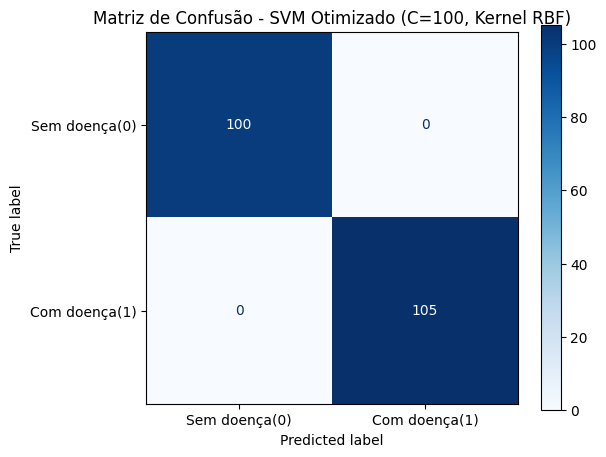

In [ ]:
# Matriz de confusão e Relatório Completo
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Previsões do modelo otimizado nos 20% de teste
y_pred_otimizado = grid_svm.predict(X_test)

# Exibir o Relatório de Classificação (Precisão , Recall, F1-Score)
print("=== RELATÓRIO DE CLASSIFICAÇÃO (SVM OTIMIZADO) ===")
print(classification_report(y_test, y_pred_otimizado))

# Plotar a Matriz de Confusão Visual
fig,ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_otimizado,
    display_labels=['Sem doença(0)', 'Com doença(1)'],
    cmap='Blues',
    ax=ax
)
plt.title("Matriz de Confusão - SVM Otimizado (C=100, Kernel RBF)")
plt.show()

MODELAGEM PREDITIVA NA BASE ELEITORAL DE 1936


In [ ]:
# =====================================================================
# PROJETO: MODELAGEM PREDITIVA NA BASE ELEITORAL DE 1936
# (SVM + ÁRVORE DE DECISÃO + RANDOM FOREST + GRADIENT BOOSTING)
# =====================================================================


# 1. Manipulação de Dados e Computação Numérica
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 2. Divisão de Dados e Otimização de Hiperparâmetros
from sklearn.model_selection import GridSearchCV, train_test_split

# 3. Pré-processamento, Transformaçoes e Pipelines
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer  # Para NLP / textos
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 4. Algoritmos de Classificação (Todas as Famílias)
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 5. Métricas de Avaliação e Gráficos de Desempenho
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)


In [ ]:
#  Carregar o arquivo bruto (57 linhas) para df_raw

df_raw = pd.read_csv('/content/LitDigestFull.csv', sep=';', header=None)

# 2. Criar a variável 'df' diretamente com os 48 estados (linhas 2 a 49)
df = pd.DataFrame()
df['State'] = df_raw.iloc[2:50, 0].values

# Função para converter números com ponto/vírgula
def converter_num(serie):
  return pd.to_numeric(
      serie.astype(str)
      .str.replace('.', '')
      .str.replace(',', '.')
      .str.strip(),
      errors='coerce',
  ).fillna(0)


df['Electoral Vote'] = converter_num(df_raw.iloc[2:50, 1]).astype(int)
df['Landon'] = converter_num(df_raw.iloc[2:50, 2])
df['Roosevelt (D)'] = converter_num(df_raw.iloc[2:50, 10])

# Correção de escala de Roosevelt
df['Roosevelt (D)'] = df['Roosevelt (D)'].apply(
    lambda x: x * 1000.0 if 0 < x < 500 else x
)

# 3. Criar a proporção e a variável Alvo (y)
df['Prop_Landon_Pesquisa'] = df['Landon'] / (
    df['Landon'] + df['Roosevelt (D)'] + 1e-5
)
df['Landon_Ajustado'] = df['Landon'] * 0.782
df['Roosevelt_Ajustado'] = df['Roosevelt (D)'] * 1.197
df['Vencedor_Ajustado'] = np.where(
    df['Landon_Ajustado'] > df['Roosevelt_Ajustado'], 'Landon', 'Roosevelt'
)

# 4. Salvar a versão tratada no Colab para garantir
df.to_csv('/content/dataset_1936_saneado.csv', index=False)

print(" SUCESSO! A variável 'df' foi criada corretamente:")
print(" Tamanho final (Linhas, Colunas):", df.shape)
df.head()

 SUCESSO! A variável 'df' foi criada corretamente:
 Tamanho final (Linhas, Colunas): (48, 8)


,State,Electoral Vote,Landon,Roosevelt (D),Prop_Landon_Pesquisa,Landon_Ajustado,Roosevelt_Ajustado,Vencedor_Ajustado
0,Alabama,NaN,NaN,NaN,NaN,NaN,NaN,Roosevelt
1,Arizona,NaN,NaN,NaN,NaN,NaN,NaN,Roosevelt
2,Arkansas,11.0,3060.0,10082.0,0.232841,2392.920,12068.154,Roosevelt
3,California,3.0,2337.0,1975.0,0.541976,1827.534,2364.075,Roosevelt
4,Colorado,9.0,2724.0,7608.0,0.263647,2130.168,9106.776,Roosevelt


In [ ]:
# =====================================================================
# SEPARAÇÃO DE X E y + DIVISÃO ESTRATIFICADA (80/20)
# =====================================================================
from sklearn.model_selection import train_test_split

# 1. Selecionar as variáveis preditoras (X) preenchendo NaNs e a alvo (y)
colunas_preditoras = [
    'Landon',
    'Roosevelt (D)',
    'Prop_Landon_Pesquisa',
    'Electoral Vote',
]

X = df[colunas_preditoras].fillna(0)
y = df['Vencedor_Ajustado']

# 2. Divisão Estratificada (80% Treino / 20% Teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


print(' DIVISÃO CONCLUÍDA COM SUCESSO!')
print(f'• Amostras de Treino: {X_train.shape[0]} estados')
print(f'• Amostras de Teste:  {X_test.shape[0]} estados')

 DIVISÃO CONCLUÍDA COM SUCESSO!
• Amostras de Treino: 38 estados
• Amostras de Teste:  10 estados


In [ ]:
# =====================================================================
# PIPELINES COM PADRONIZAÇÃO E AVALIAÇÃO MULTIMODELO
# =====================================================================

# 1. Definir os modelos dentro de Pipelines
modelos = {
    'SVM (RBF Padronizado)': Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(C=10, kernel='rbf', random_state=42)),
    ]),
    'Regressão Logística': Pipeline([
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    ),  # <-- Incluído no dicionário
}

# 2. Treinar cada modelo e calcular a acurácia no teste
resultados = []
for nome, modelo in modelos.items():
  modelo.fit(X_train, y_train)
  y_pred = modelo.predict(X_test)
  acc = accuracy_score(y_test, y_pred)
  resultados.append({'Modelo': nome, 'Acurácia (%)': round(acc * 100, 2)})

# 3. Exibir a tabela comparativa ordenada
df_comparativo = pd.DataFrame(resultados).sort_values(
    by='Acurácia (%)', ascending=False
)

print('=== TABELA COMPARATIVA DE DESEMPENHO ===')
display(df_comparativo)

=== TABELA COMPARATIVA DE DESEMPENHO ===


,Modelo,Acurácia (%)
2,Árvore de Decisão,100.0
4,Gradient Boosting,100.0
3,Random Forest,100.0
1,Regressão Logística,90.0
0,SVM (RBF Padronizado),80.0


===  RESULTADOS DA VALIDAÇÃO CRUZADA (5-FOLD CV) ===
• Melhor Acurácia na Validação Cruzada: 95.00%
• Melhores Hiperparâmetros: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}

===  RELATÓRIO DE CLASSIFICAÇÃO NO TESTE ===
              precision    recall  f1-score   support

      Landon       1.00      0.67      0.80         3
   Roosevelt       0.88      1.00      0.93         7

    accuracy                           0.90        10
   macro avg       0.94      0.83      0.87        10
weighted avg       0.91      0.90      0.89        10



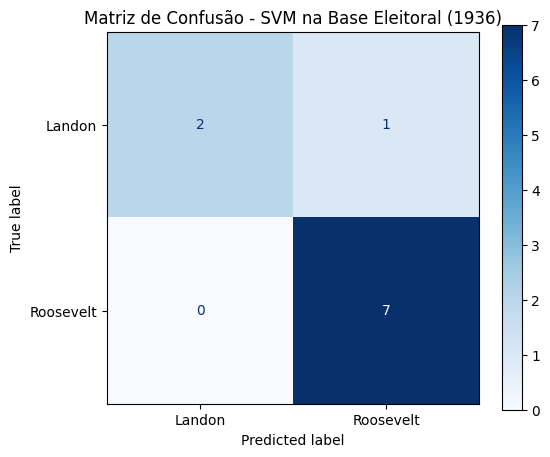

In [ ]:
# =====================================================================
# GRIDSEARCHCV (5-FOLD CV) E MATRIZ DE CONFUSÃO DO SVM
# =====================================================================

# 1. Grade de Hiperparâmetros para busca no SVM
param_grid = {
    'svm__C': [0.1, 1, 10, 50],
    'svm__kernel': ['rbf', 'linear'],
    'svm__gamma': ['scale', 'auto'],
}

grid_svm = GridSearchCV(
    estimator=modelos['SVM (RBF Padronizado)'],
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
)

grid_svm.fit(X_train, y_train)

print('===  RESULTADOS DA VALIDAÇÃO CRUZADA (5-FOLD CV) ===')
print(
    '• Melhor Acurácia na Validação Cruzada:'
    f' {grid_svm.best_score_ * 100:.2f}%'
)
print(f'• Melhores Hiperparâmetros: {grid_svm.best_params_}\n')

# 2. Avaliação Final no Teste com o Melhor Modelo
melhor_svm = grid_svm.best_estimator_
y_pred_otimizado = melhor_svm.predict(X_test)

print('===  RELATÓRIO DE CLASSIFICAÇÃO NO TESTE ===')
print(classification_report(y_test, y_pred_otimizado))

# 3. Gráfico da Matriz de Confusão
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_otimizado,
    display_labels=melhor_svm.classes_,
    cmap='Blues',
    ax=ax,
)
plt.title('Matriz de Confusão - SVM na Base Eleitoral (1936)')
plt.show()

FISHMORPH

In [ ]:
import kagglehub
path = kagglehub.dataset_download("menegidio/fishmorph-dataset")

Using Colab cache for faster access to the 'fishmorph-dataset' dataset.


In [ ]:
# =====================================================================
# CÉLULA 1: IMPORTAÇÕES DAS BIBLIOTECAS DE MACHINE LEARNING
# =====================================================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Scikit-Learn: Pré-processamento e Divisão dos Dados
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

# 2. Scikit-Learn: Algoritmos de Classificação
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# 3. Scikit-Learn: Métricas de Avaliação de Desempenho
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


In [ ]:
# =====================================================================
# CELULA 2: CARREGAR A BASE DE DADOS E VISUALIZAR AS PRIMEIRAS LINHAS
# =====================================================================
import os
import pandas as pd

# 1. Procurar arquivos .csv dentro da pasta do dataset baixado pelo Kaggle
arquivos_csv = []
for raiz, pastas, arquivos in os.walk(path):
    for arquivo in arquivos:
        if arquivo.endswith('.csv'):
            arquivos_csv.append(os.path.join(raiz, arquivo))

print("Arquivo CSV encontrado:", arquivos_csv)

# 2. Carregar o arquivo .csv no DataFrame do Pandas
if arquivos_csv:
    caminho_csv = arquivos_csv[0]
    df_fish = pd.read_csv(caminho_csv)

    print("Base de peixes carregada com sucesso!")
    print("Dimensoes da tabela (Linhas, Colunas):", df_fish.shape)
    print("\nPrimeiras 5 linhas do dataset:")
    display(df_fish.head())
else:
    print("Nenhum arquivo .csv foi encontrado na pasta:")
    print(os.listdir(path))

Arquivo CSV encontrado: ['/kaggle/input/fishmorph-dataset/FISHMORPH_Order_Dataset.csv', '/kaggle/input/fishmorph-dataset/FISHMORPH_Family_Dataset.csv']
Base de peixes carregada com sucesso!
Dimensoes da tabela (Linhas, Colunas): (8342, 11)

Primeiras 5 linhas do dataset:


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Order
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991,Cypriniformes
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592,Perciformes
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580,Cypriniformes
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062,Cypriniformes
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906,Cypriniformes


In [ ]:
# =====================================================================
# CELULA 3: SEPARACAO AUTOMATICA DE X E y + DIVISAO (80/20)
# =====================================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. X recebe tudo, EXCETO a coluna alvo 'Order'
X = df_fish.drop(columns=['Order']).fillna(0)

# 2. y recebe a coluna alvo 'Order' codificada em números
le = LabelEncoder()
y = le.fit_transform(df_fish['Order'])

# 3. Divisão Estratificada (80% Treino / 20% Teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Divisao concluida com sucesso!')
print('Amostras para Treinamento (linhas, colunas):', X_train.shape)
print('Amostras para Teste (linhas, colunas):', X_test.shape)
print('Quantidade de ordens/especies distintas:', len(le.classes_))

Divisao concluida com sucesso!
Amostras para Treinamento (linhas, colunas): (6673, 10)
Amostras para Teste (linhas, colunas): (1669, 10)
Quantidade de ordens/especies distintas: 32


In [ ]:
# =====================================================================
# CELULA 4: PIPELINES COM PADRONIZACAO E AVALIACAO MULTIMODELO
# =====================================================================
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier # <-- 1. Importado aqui
from sklearn.metrics import accuracy_score

# 1. Definir os modelos em Pipelines para evitar Data Leakage
modelos = {
    'SVM (RBF Padronizado)': Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(C=10, kernel='rbf', random_state=42))
    ]),
    'Regressao Logistica': Pipeline([
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Arvore de Decisao': DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42) # <-- 2. Adicionado no dicionario
}

# 2. Treinar cada modelo e calcular a acuracia no teste
resultados = []
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acuracia (%)': round(acc * 100, 2)})

# 3. Exibir a tabela comparativa ordenada
df_comparativo = pd.DataFrame(resultados).sort_values(by='Acuracia (%)', ascending=False)

print("=== TABELA COMPARATIVA DE DESEMPENHO ===")
display(df_comparativo)

=== TABELA COMPARATIVA DE DESEMPENHO ===


,Modelo,Acuracia (%)
0,SVM (RBF Padronizado),78.31
3,Random Forest,77.29
4,Gradient Boosting,73.88
1,Regressao Logistica,68.54
2,Arvore de Decisao,65.43


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


=== RESULTADOS DA VALIDACAO CRUZADA (5-FOLD CV) ===
Melhor Acuracia na Validacao Cruzada: 79.29%
Melhores Hiperparametros encontrados: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

=== RELATORIO DE CLASSIFICACAO NO TESTE ===
              precision    recall  f1-score   support

           0       1.00      0.60      0.75         5
           2       0.75      1.00      0.86         3
           3       0.80      0.80      0.80        15
           4       0.00      0.00      0.00         1
           5       0.88      0.88      0.88         8
           6       0.82      0.70      0.76       281
           7       0.43      0.29      0.34        21
           8       0.63      0.82      0.71       356
           9       0.80      0.86      0.83       118
          11       1.00      0.25      0.40         4
          12       0.00      0.00      0.00         1
          13       0.67      1.00      0.80         2
          15       0.00      0.00      0.00         2
   

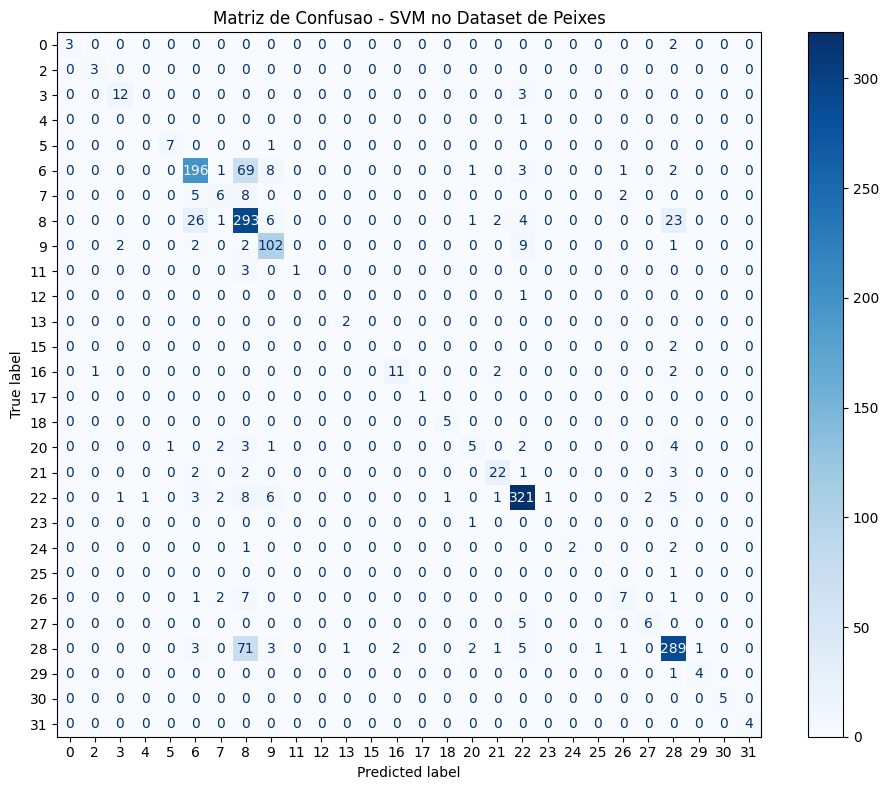

In [ ]:
# =====================================================================
# CELULA 5: GRIDSEARCHCV (5-FOLD CV) E MATRIZ DE CONFUSAO DO SVM
# =====================================================================
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV

# 1. Definir a grade de hiperparametros para busca no SVM
param_grid = {
    'svm__C': [0.1, 1, 10, 50],
    'svm__kernel': ['rbf', 'linear'],
    'svm__gamma': ['scale', 'auto'],
}

# 2. Configurar o GridSearchCV com 5-Fold Cross-Validation
grid_svm = GridSearchCV(
    estimator=modelos['SVM (RBF Padronizado)'],
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
)

# 3. Executar o treinamento da busca
grid_svm.fit(X_train, y_train)

print('=== RESULTADOS DA VALIDACAO CRUZADA (5-FOLD CV) ===')
print(
    'Melhor Acuracia na Validacao Cruzada:'
    f' {grid_svm.best_score_ * 100:.2f}%'
)
print('Melhores Hiperparametros encontrados:', grid_svm.best_params_)
print()

# 4. Avaliar o melhor modelo no conjunto de teste
melhor_svm = grid_svm.best_estimator_
y_pred_otimizado = melhor_svm.predict(X_test)

print('=== RELATORIO DE CLASSIFICACAO NO TESTE ===')
print(classification_report(y_test, y_pred_otimizado, zero_division=0))

# 5. Plotar a Matriz de Confusao
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_otimizado, cmap='Blues', ax=ax
)
plt.title('Matriz de Confusao - SVM no Dataset de Peixes')
plt.tight_layout()
plt.show()

No projeto do FishMorph Dataset, utilizamos 6.673 amostras para treino e 1.669 para teste, classificando os peixes em 32 ordens biológicas com base em 10 medidas morfológicas. Comparando os algoritmos, o SVM com Kernel RBF e padronização dos dados foi o vencedor absoluto com 78,31% de acurácia no teste e 79,29% na validação cruzada, superando o Random Forest (77,29%), a Regressão Logística (68,54%) e a Árvore de Decisão (65,43%)."

INDIAN CREDIT CARD

In [ ]:
import kagglehub
path = kagglehub.dataset_download("babbaransh12/indian-credit-card")

Using Colab cache for faster access to the 'indian-credit-card' dataset.


In [ ]:
# =====================================================================
# CÉLULA 1: IMPORTAÇÕES E CARREGAMENTO DO DATASET VIA KAGGLEHUB
# =====================================================================
import os
import re
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pré-processamento, Pipelines e Validação
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Algoritmos de Classificação (5 Famílias)
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Métricas de Avaliação
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)


In [ ]:
# 1. Download/Acesso ao Dataset via KaggleHub
path = kagglehub.dataset_download("babbaransh12/indian-credit-card")
csv_path = os.path.join(path, "credit_1.csv")

# 2. Carregamento da base bruta
df = pd.read_csv(csv_path)

print(" Dataset baixado e carregado com sucesso via kagglehub!")
print(f"• Caminho local: {csv_path}")
print(f"• Dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas.\n")
display(df.head(3))

Using Colab cache for faster access to the 'indian-credit-card' dataset.
 Dataset baixado e carregado com sucesso via kagglehub!
• Caminho local: /kaggle/input/indian-credit-card/credit_1.csv
• Dimensões: 366 linhas e 15 colunas.



,Card Name,Issuer,Annual Fee,Min Income,Credit Limit,Cashback %,Reward Rate,Reward Type,Category,Forex Fee,Lounge Access,Joining Bonus,Spend Requirement,Key Benefits,Best For
0,Infinia Metal,HDFC Bank,"₹12,500",₹3L+/month,8L–20L,~3.3%,5X–10X,Reward Points,Super Premium,~2%,Unlimited Global,Yes,₹4L/qtr,"Luxury perks, concierge",HNI users
1,Diners Club Black,HDFC Bank,"₹10,000",₹1.75L+/month,5L–15L,~3%,5X–10X,Reward Points,Premium,~2%,Unlimited,Yes,₹5L/year,SmartBuy rewards,Frequent travelers
2,Regalia Gold,HDFC Bank,"₹2,500",₹1L+/month,3L–10L,~1–2%,4X–5X,Reward Points,Travel,~2%,12/year,Yes,₹1.5L/qtr,Travel vouchers,Mid-high income


In [ ]:
# =====================================================================
# CÉLULA 2: LIMPEZA DE DADOS, REGEX E ENGENHARIA DE RECURSOS
# =====================================================================
import re

# 1. Função para extrair apenas o valor numérico de textos com símbolos (₹, %, etc.)
def extrair_num(val):
  # Busca a sequência numérica (inteiro ou decimal) removendo vírgulas
  match = re.search(r'(\d+\.?\d*)', str(val).replace(',', ''))
  return float(match.group(1)) if match else 0.0


# 2. Tratamento do sistema numérico indiano (Lakhs e Thousands) e conversão para Rúpias anuais
def converter_renda(val):
  s = str(val).replace(',', '').lower()
  # Define o multiplicador: Lakh (L) = 100.000, Thousand (k) = 1.000
  fator = 100000 if 'l' in s else (1000 if 'k' in s else 1)
  # Se a cotação for mensal (/month), multiplica por 12 para anualizar a renda
  if 'month' in s:
    fator *= 12
  return extrair_num(val) * fator


# 3. Aplicação da limpeza nas colunas numéricas financeiras
df['annual_fee_num'] = df['Annual Fee'].apply(extrair_num)  # Anuidade
df['min_income_num'] = df['Min Income'].apply(
    converter_renda
)  # Renda mínima anualizada
df['cashback_num'] = df['Cashback %'].apply(extrair_num)  # Percentual de cashback
df['forex_num'] = df['Forex Fee'].apply(extrair_num)  # Taxa de câmbio

# 4. Concatenação dos textos de benefícios para Processamento de Linguagem Natural (PLN / TF-IDF)
df['text_combined'] = (
    df['Key Benefits'].fillna('') + ' ' + df['Best For'].fillna('')
)
df['Issuer'] = df['Issuer'].fillna(
    'Outros'
)  # Preenchimento de nulos no banco emissor

# 5. Agrupamento da anuidade em 4 faixas de preço (Alvo do Cenário 2) via pd.cut
limites = [-1, 0, 1000, 5000, float('inf')]
rotulos = ['Isento (Grátis)', 'Baixo (<= ₹1k)', 'Médio (₹1k-₹5k)', 'Alto (> ₹5k)']
df['Fee_Tier'] = pd.cut(df['annual_fee_num'], bins=limites, labels=rotulos)

print('✅ Limpeza e criação de atributos concluídas com sucesso!')
display(
    df[[
        'annual_fee_num',
        'min_income_num',
        'cashback_num',
        'forex_num',
        'Fee_Tier',
    ]].head(3)
)

✅ Limpeza e criação de atributos concluídas com sucesso!


,annual_fee_num,min_income_num,cashback_num,forex_num,Fee_Tier
0,12500.0,3600000.0,3.3,2.0,Alto (> ₹5k)
1,10000.0,2100000.0,3.0,2.0,Alto (> ₹5k)
2,2500.0,1200000.0,1.0,2.0,Médio (₹1k-₹5k)


In [ ]:
# =====================================================================
# CÉLULA 3: DIVISÃO 80/20 E COLUMNTRANSFORMER (CORRIGIDA)
# =====================================================================

# 1. Filtra faixas com pelo menos 5 amostras para permitir amostragem estratificada
counts = df['Fee_Tier'].value_counts()
valid_tiers = counts[counts >= 5].index
df_tier = df[df['Fee_Tier'].isin(valid_tiers)].copy()

# 2. Definição do X (sem anuidade exata para evitar data leakage) e y (Fee_Tier)
X = df_tier[
    ['min_income_num', 'cashback_num', 'forex_num', 'Issuer', 'text_combined']
]
y = df_tier['Fee_Tier']

# 3. Divisão 80% Treino e 20% Teste Estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. ColumnTransformer: StandardScaler (números), OneHotEncoder (banco) e TF-IDF (texto)
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), ['min_income_num', 'cashback_num', 'forex_num']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['Issuer']),
    (
        'text',
        TfidfVectorizer(max_features=120, stop_words='english'),
        'text_combined',
    ),
])

print(
    f' Divisão 80/20 concluída! Treino: {X_train.shape} | Teste:'
    f' {X_test.shape}'
)

 Divisão 80/20 concluída! Treino: (292, 5) | Teste: (74, 5)


In [ ]:
# =====================================================================
# CÉLULA 4: AVALIAÇÃO MULTIMODELO (COMPACTA E COM PRINT GARANTIDO)
# =====================================================================

print(" Treinando e avaliando os 5 modelos (aguarde alguns segundos)...")

# 1. Dicionário com os 5 algoritmos de classificação
modelos = {
    'SVM (RBF)': SVC(C=50, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Regressão Logística': LogisticRegression(max_iter=1000, random_state=42),
}

# 2. Treinamento dinâmico de cada Pipeline e cálculo da acurácia
res = []
for nome, clf in modelos.items():
  pipe = Pipeline([('prep', preprocessor), ('m', clf)])
  pipe.fit(X_train, y_train)
  acc = accuracy_score(y_test, pipe.predict(X_test))
  res.append({'Modelo': nome, 'Acurácia (%)': round(acc * 100, 2)})

# 3. Exibição da Tabela Comparativa Ordenada
df_res = pd.DataFrame(res).sort_values(by='Acurácia (%)', ascending=False)

print('\n===  TABELA COMPARATIVA DE DESEMPENHO MULTIMODELO ===')
display(df_res)


 Treinando e avaliando os 5 modelos (aguarde alguns segundos)...

===  TABELA COMPARATIVA DE DESEMPENHO MULTIMODELO ===


,Modelo,Acurácia (%)
1,Gradient Boosting,71.62
2,Random Forest,71.62
0,SVM (RBF),70.27
4,Regressão Logística,66.22
3,Árvore de Decisão,54.05


• Melhor Acurácia na CV (3-Fold): 71.57%

• Melhores Hiperparâmetros: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}

=== RELATÓRIO DE CLASSIFICAÇÃO NO TESTE ===
                 precision    recall  f1-score   support

   Alto (> ₹5k)       0.54      1.00      0.70         7
 Baixo (<= ₹1k)       0.72      0.77      0.74        30
Isento (Grátis)       0.68      0.62      0.65        21
Médio (₹1k-₹5k)       0.80      0.50      0.62        16

       accuracy                           0.69        74
      macro avg       0.69      0.72      0.68        74
   weighted avg       0.71      0.69      0.68        74



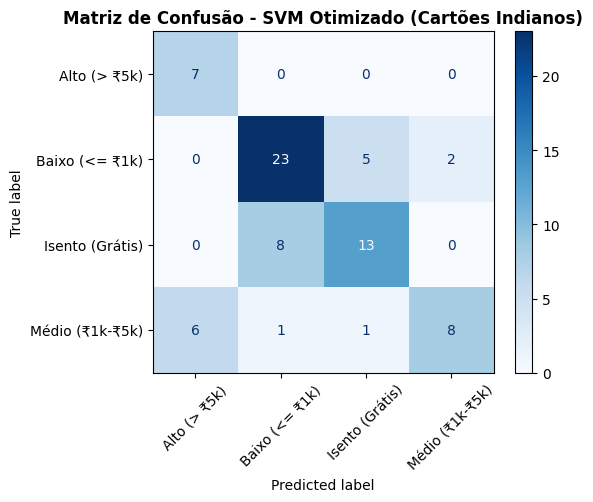

In [ ]:
# =====================================================================
# CÉLULA 5: GRIDSEARCHCV E MATRIZ DE CONFUSÃO DO SVM
# =====================================================================

# 1. Grade de busca para otimização dos hiperparâmetros do SVM
param_grid = {
    'svm__C': [0.1, 1, 10, 50],
    'svm__kernel': ['rbf', 'linear'],
    'svm__gamma': ['scale', 'auto'],
}

# 2. Busca exaustiva com Validação Cruzada (3-Fold CV)
grid_svm = GridSearchCV(
    estimator=Pipeline(
        [('prep', preprocessor), ('svm', SVC(random_state=42))]
    ),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
)
grid_svm.fit(X_train, y_train)

print(
    '• Melhor Acurácia na CV (3-Fold):'
    f' {grid_svm.best_score_ * 100:.2f}%\n'
)
print(f'• Melhores Hiperparâmetros: {grid_svm.best_params_}\n')

# 3. Avaliação no conjunto de teste e Matriz de Confusão
y_pred_svm = grid_svm.predict(X_test)
print('=== RELATÓRIO DE CLASSIFICAÇÃO NO TESTE ===')
print(classification_report(y_test, y_pred_svm))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm, cmap='Blues', ax=ax, xticks_rotation=45
)
plt.title(
    'Matriz de Confusão - SVM Otimizado (Cartões Indianos)', fontweight='bold'
)
plt.tight_layout()
plt.show()